# introductory text (explain: dataset, task)

I am working with a dataset of DnD characters that stores any and all information found in an online character sheet within the website DnD Beyond. The feature I will be attempting to predict for is charatcer class, like barbarian, bard, wizard, etc. These characters can sometimes be very similar (Like warlocks and wizards) but there are generally distinct when it comes to stats. For instance a barbarian with high intelligence and low strength is a large mismatch for the capabilities of the class, while high intelligence is a perfect stat for a wizard, making that class a better fit. The stat categories are: Strength, Dexterity, Constitution, Intelligence, Wisdom, and Charisma. These stats affect various aspects of DnD, from adding a modifer to certain dice rolls, to unlocking access to different sets of skills/spells. My datset has ~1.4 million different character entries. Aside from the stats, hp, and level totals, there are also columns that are not very useful or completely irrelevent. Gold, Name, subclss_starting, class_other, subclass_other, inventory, date_modifed, notes_len, char_id and Unnamed: 0 are completely useless as they are fully independent on stats or class. Race, background, and feats, do effect stats somewhat but these are all categorical features, and the effect is usually incredibly minor. These columns would've added complexity my dataset definetly did not need, so I dropped them from the prediction.

# import requisite modules

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score, precision_score, recall_score
from time import localtime, strftime
from sklearn.preprocessing import LabelEncoder

# helper functions (if necessary)

In [2]:
# python code

# pre-process, analyze dataset

In [3]:
df = pd.read_csv("over_one_mil_chars.csv")


df = df.drop(["gold", "name", "background", "race", "subclass_starting",
              "class_other", "subclass_other", "feats", "inventory",
              "date_modified", "notes_len", "Unnamed: 0", "char_id"], axis=1)


X = df.drop("class_starting", axis=1)
y = df["class_starting"]

# visualize dataset

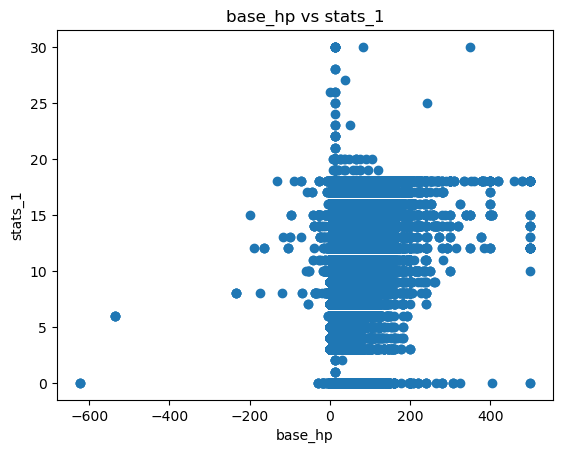

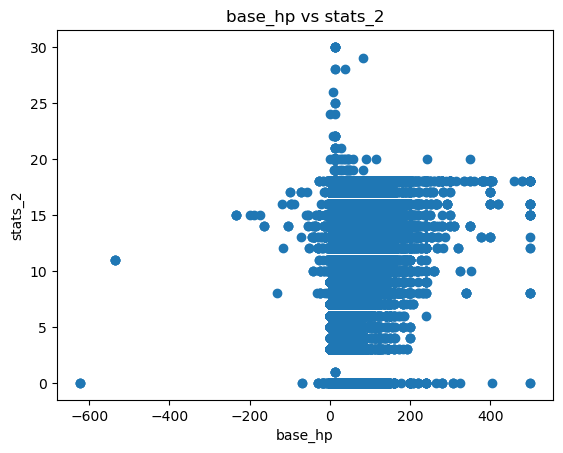

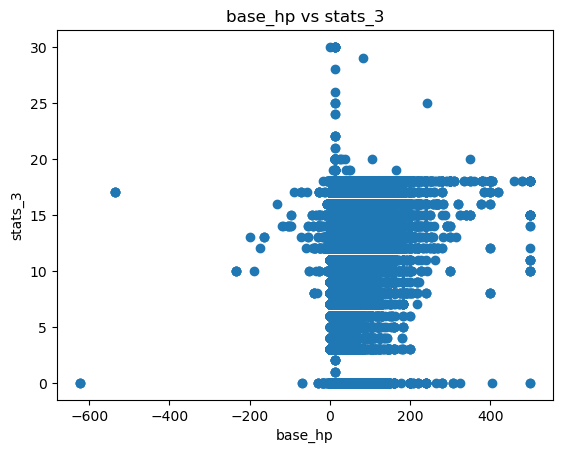

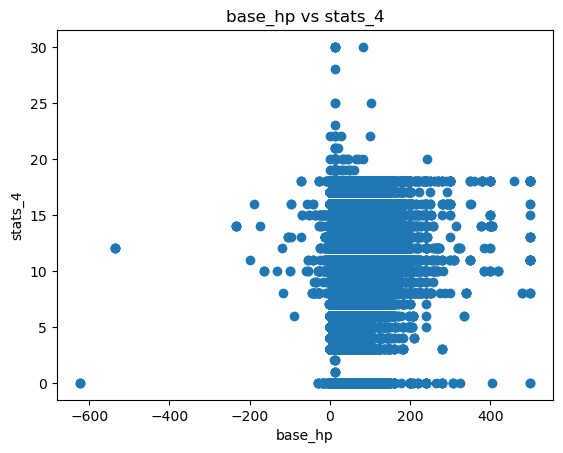

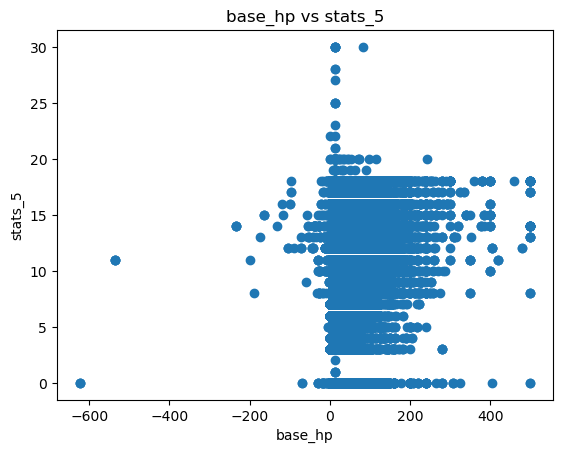

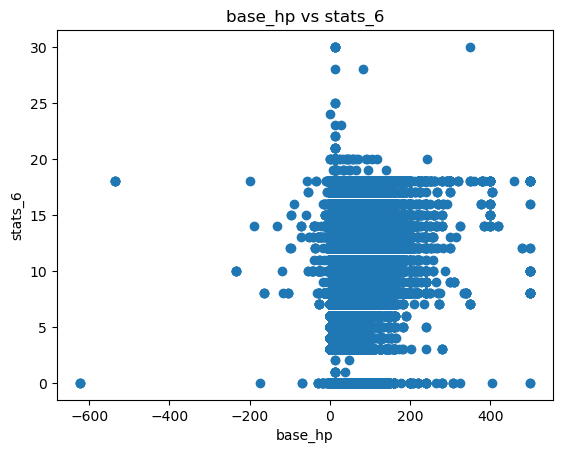

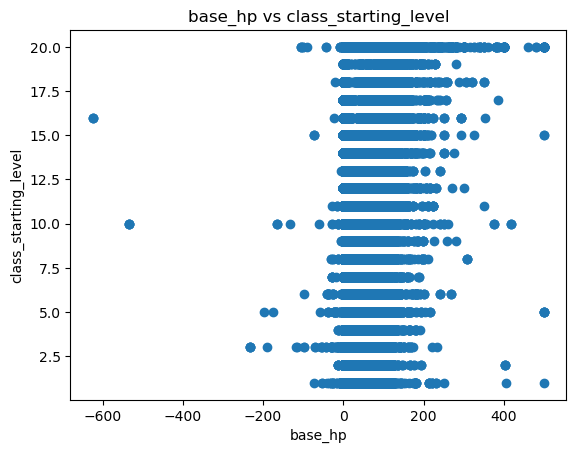

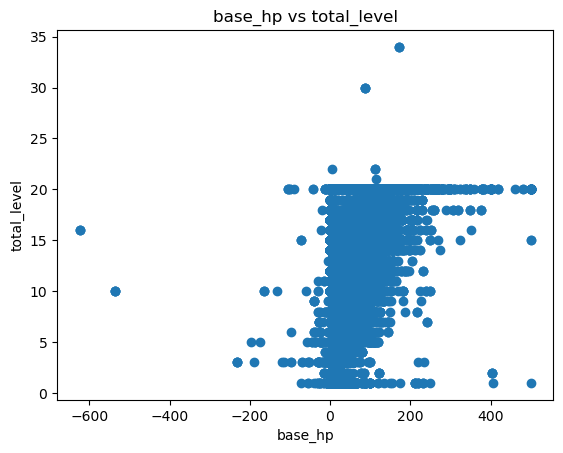

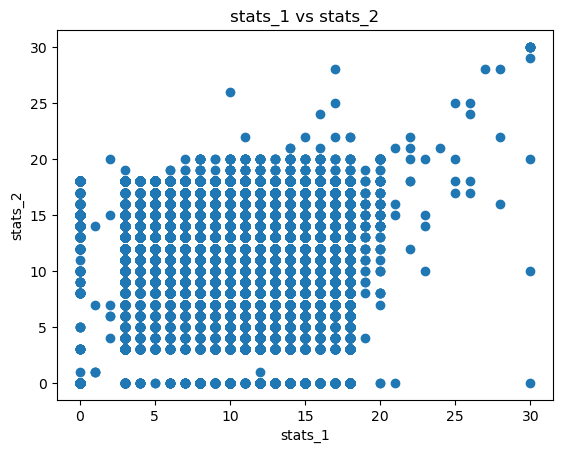

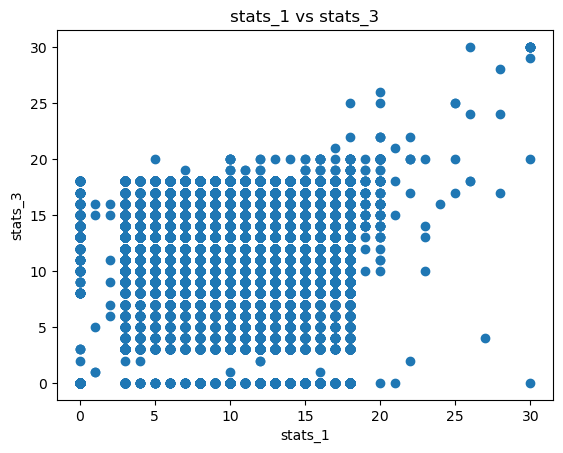

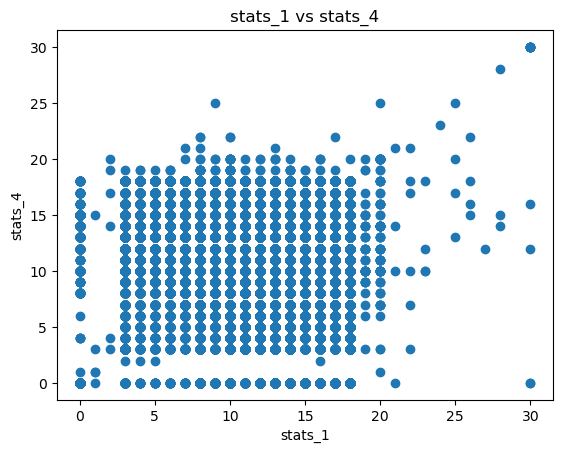

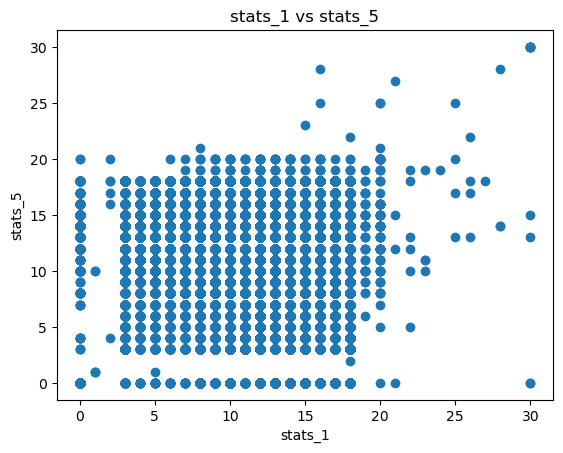

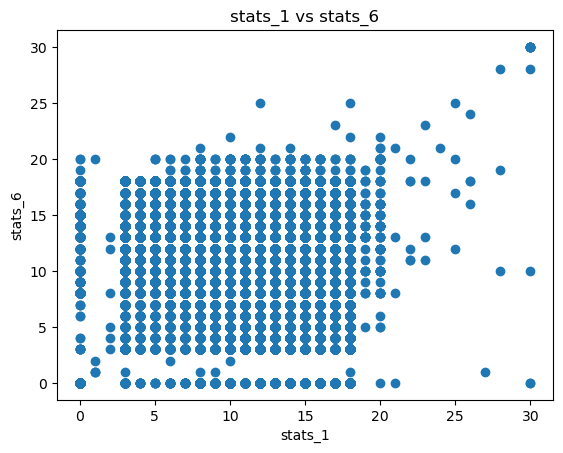

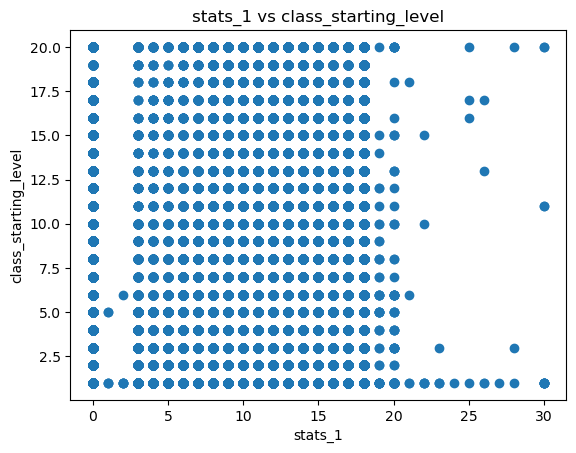

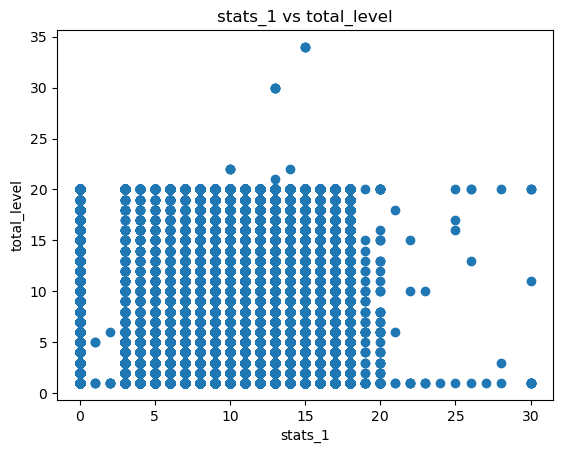

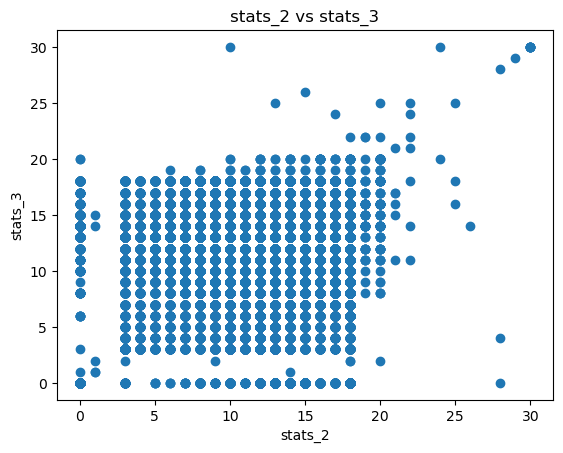

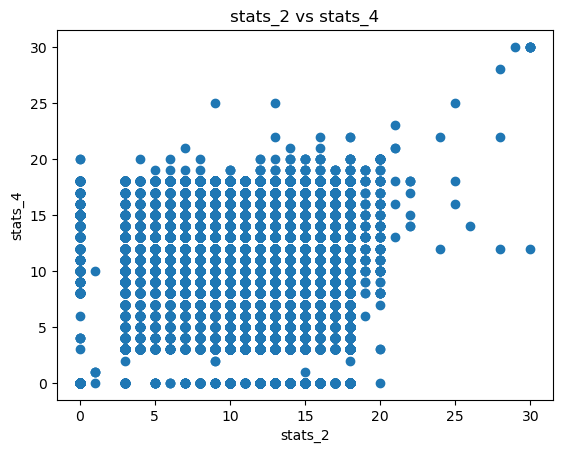

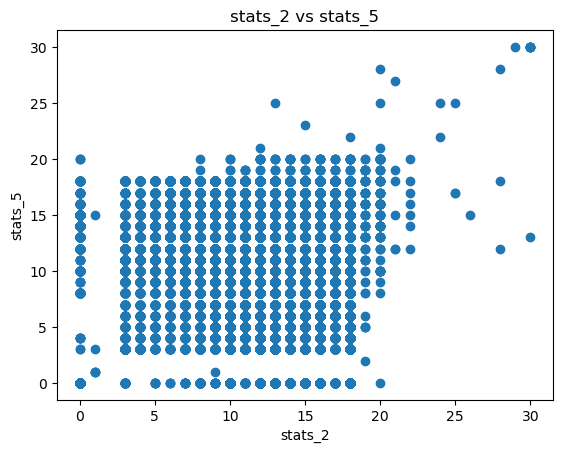

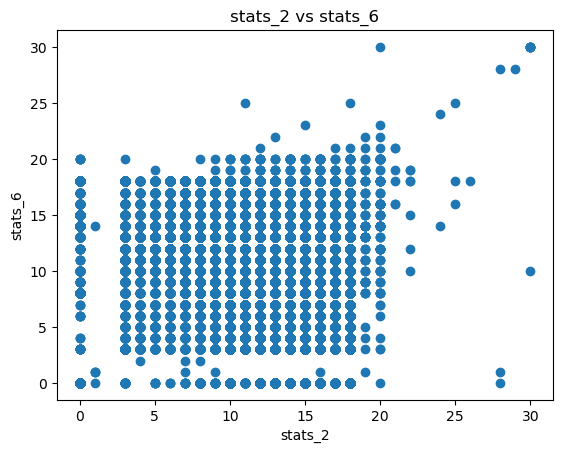

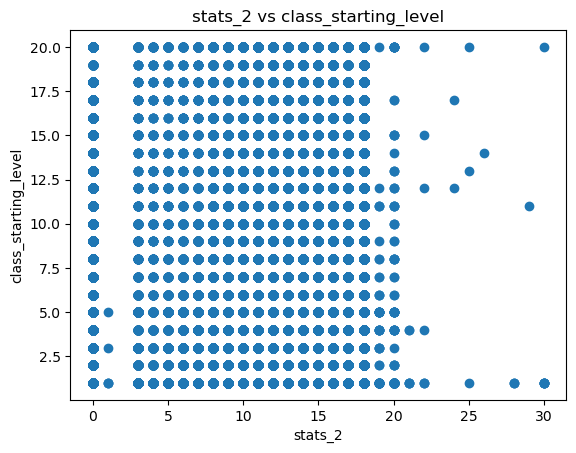

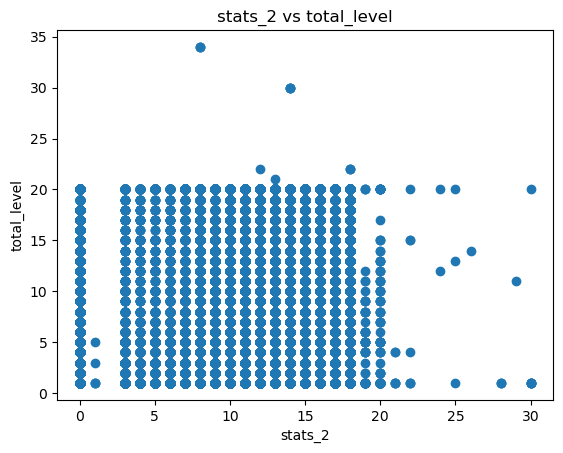

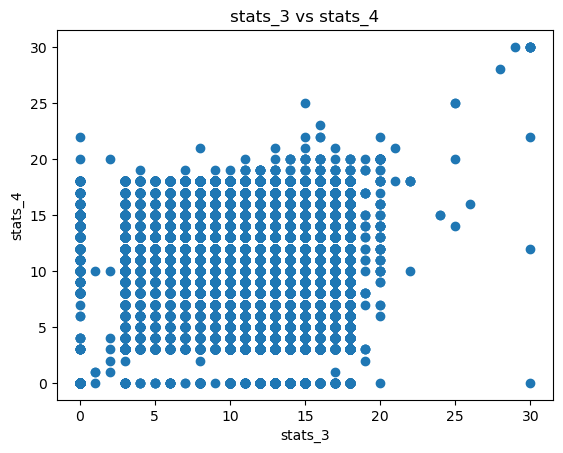

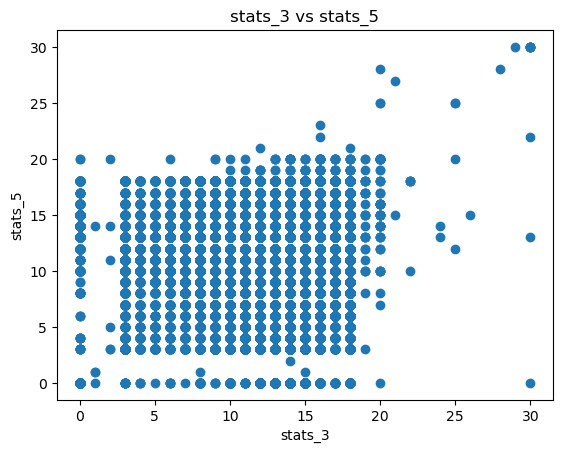

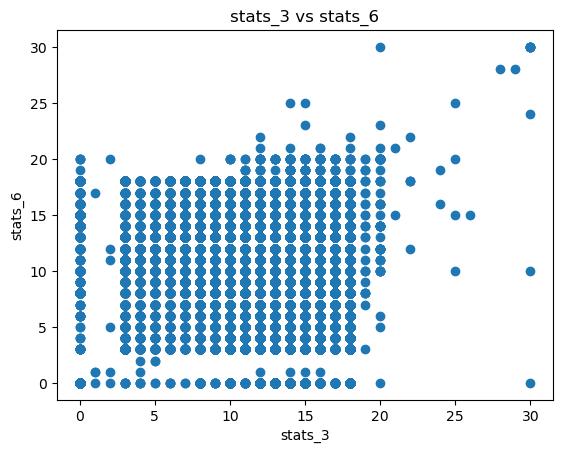

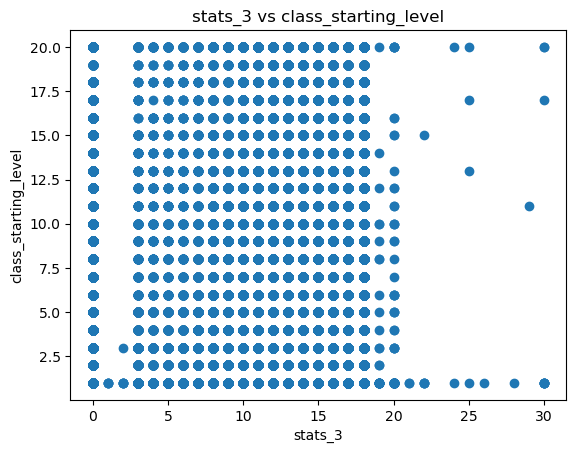

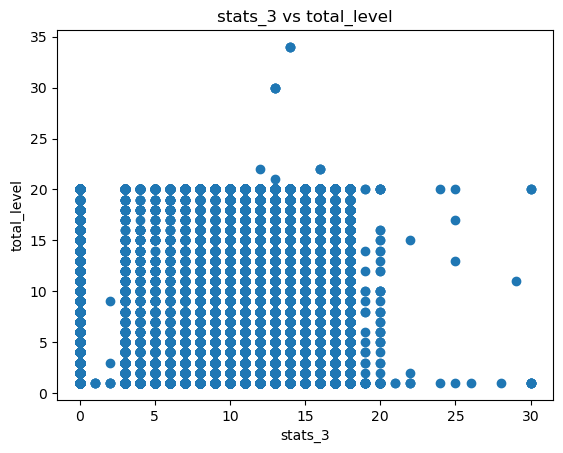

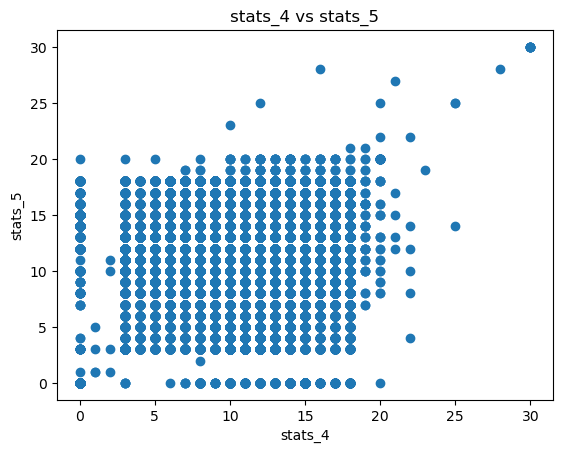

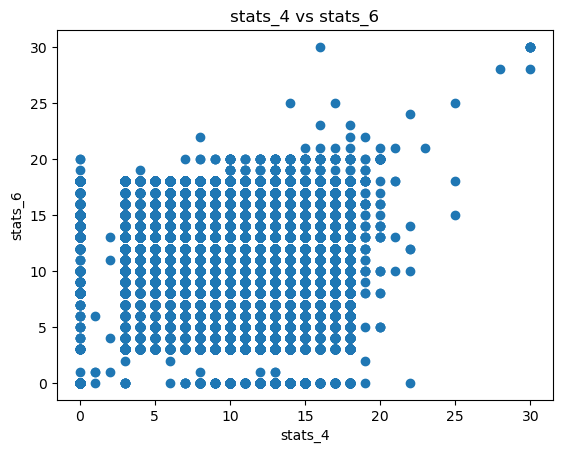

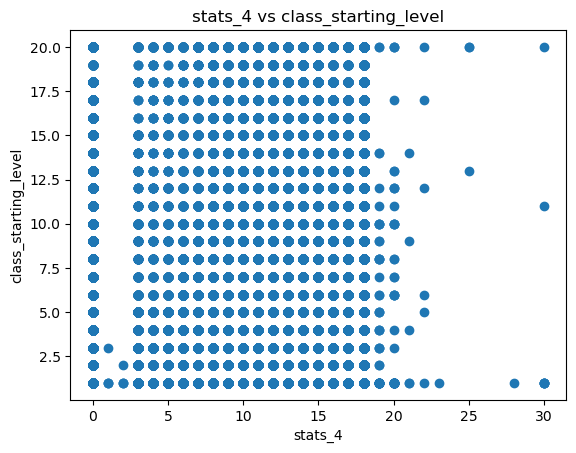

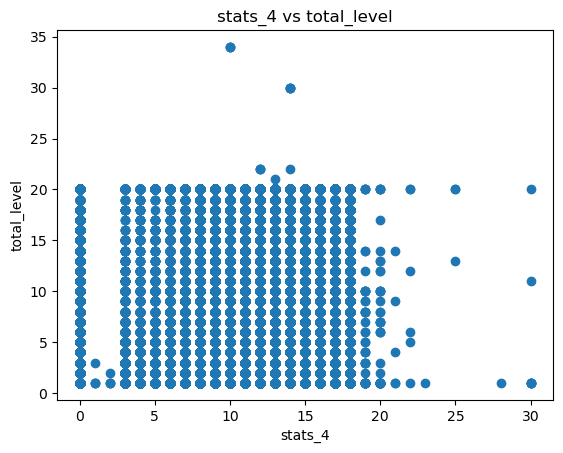

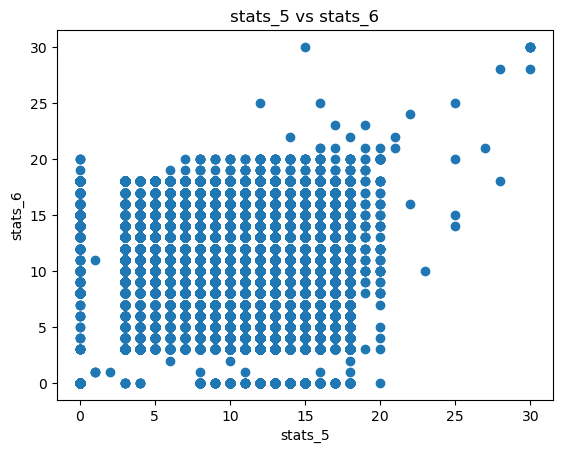

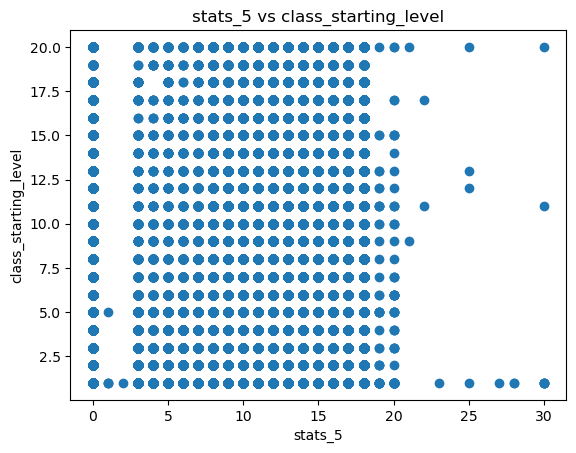

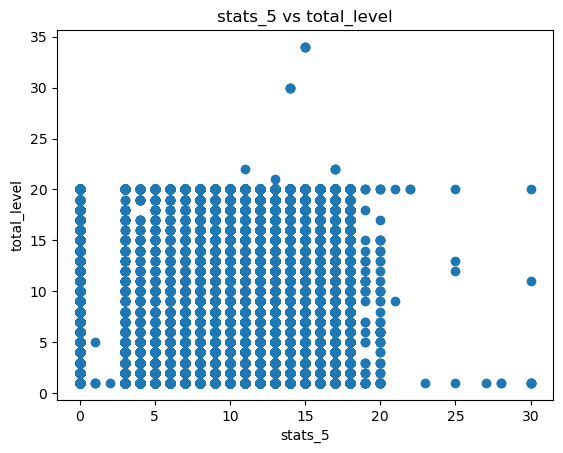

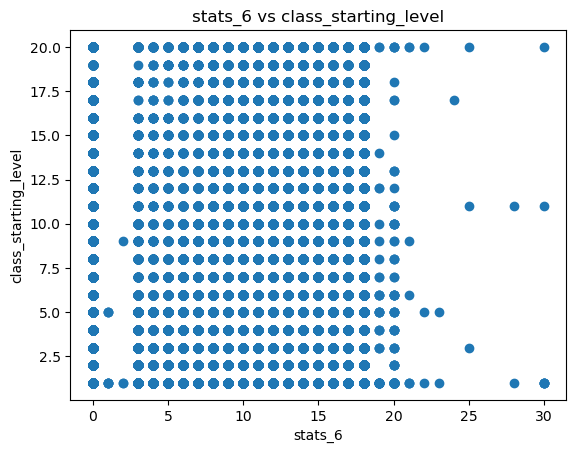

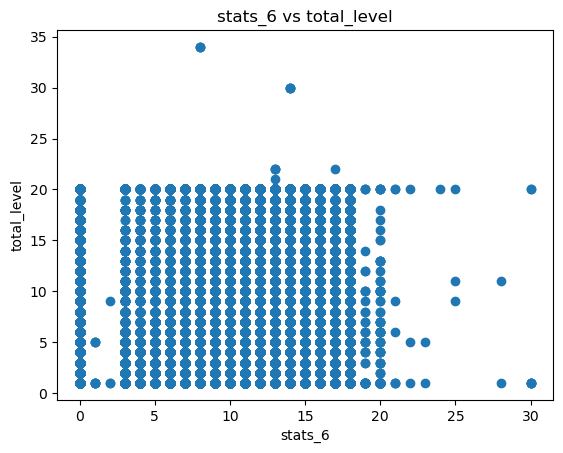

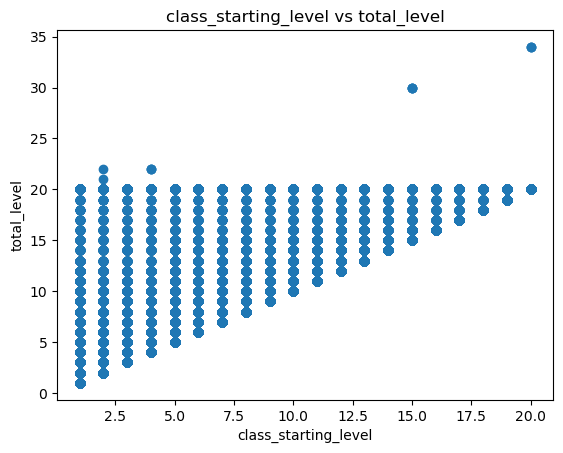

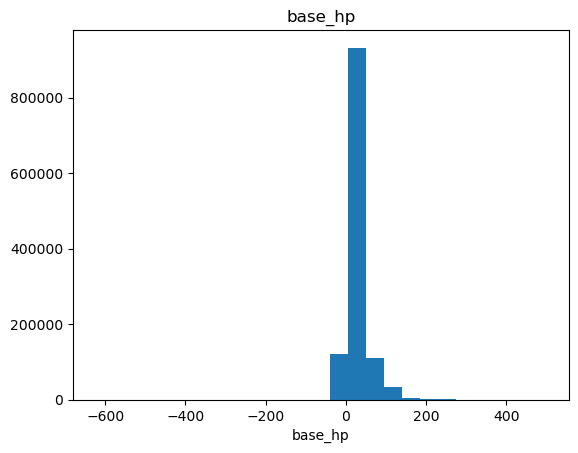

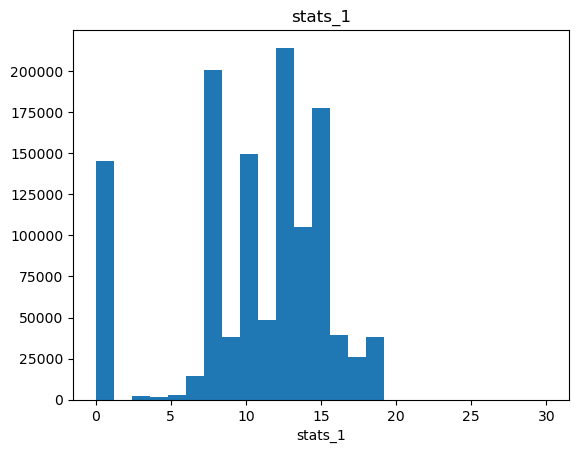

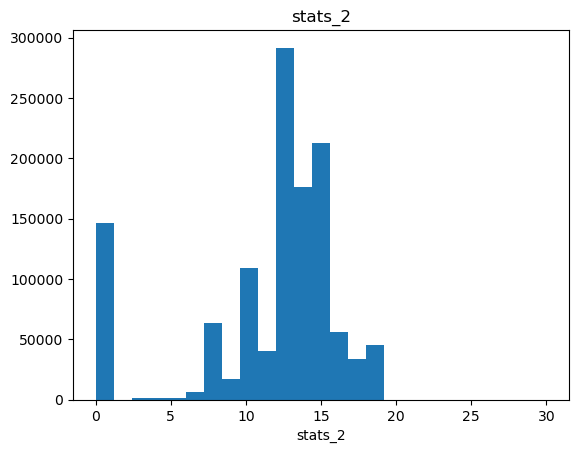

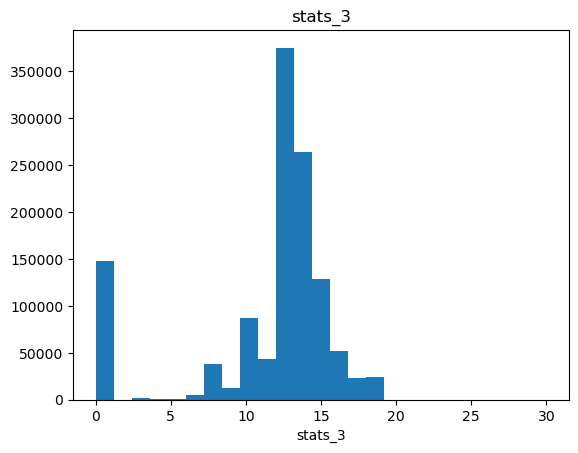

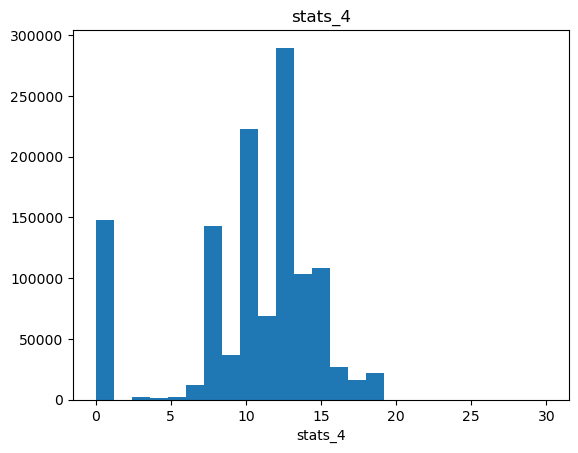

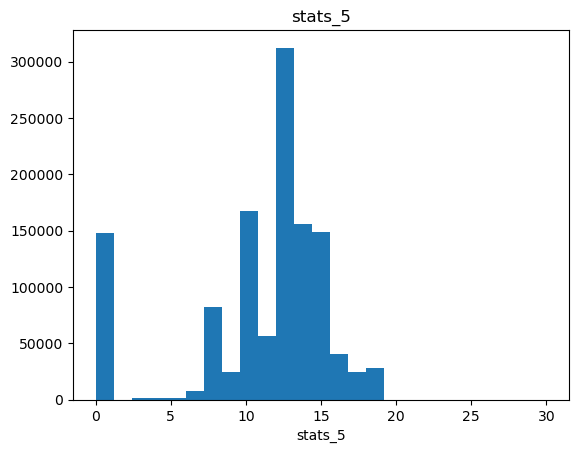

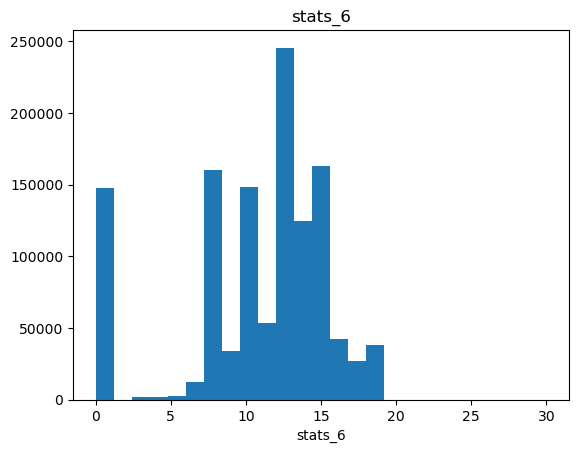

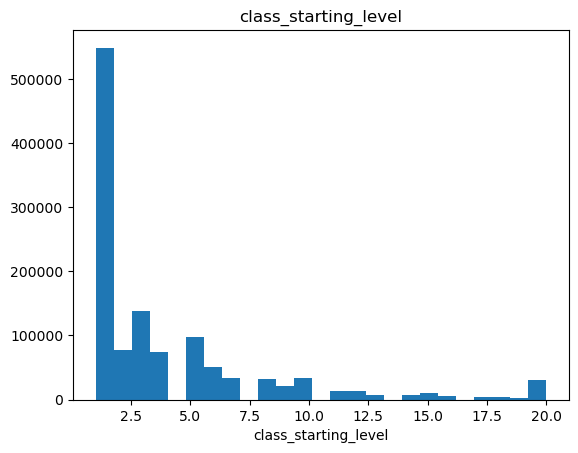

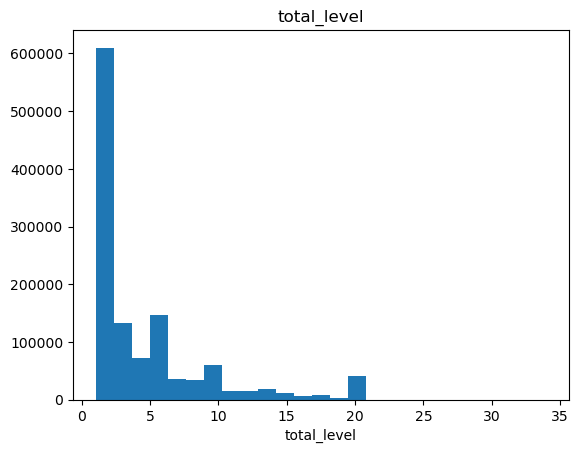

In [4]:
features = X.columns

for i in range(len(features)):
    for j in range(i+1, len(features)):
        plt.figure()
        plt.scatter(X[features[i]], X[features[j]])
        plt.xlabel(features[i])
        plt.ylabel(features[j])
        plt.title(f"{features[i]} vs {features[j]}")
        plt.show()
 
for feature in features:
    plt.figure()
    plt.hist(X[feature], bins=25)
    plt.xlabel(feature)
    plt.title(feature)
    plt.show()

# experiment with algorithms, feature sets, parameters, etc.,

In [5]:
le = LabelEncoder()
y = le.fit_transform(y)

X_train, X_validate, y_train, y_validate = train_test_split(X,y, train_size=0.8, test_size=0.2, shuffle=True, stratify=y)
X_small, X_val_sm, y_small, y_val_sm = train_test_split(X, y, train_size=20000,test_size=20000, shuffle=True, stratify=y) #used to tune hyperparameters of DT

"""
Jupiter kept crashing when I tried running this here, but in spyder the accuracy was anywhere from ~50% to ~65% at the highest
I eventually moved on to Random Forests instead.

# decision tree
dt = DecisionTreeClassifier(criterion="entropy", max_depth=20, min_samples_split=50, min_samples_leaf=20)
results = dt.cost_complexity_pruning_path(X_train, y_train)

#num = 1
alpha_vals = {}
for alpha in results["ccp_alphas"]:
    if alpha < 0:
        continue
    
    model = DecisionTreeClassifier(criterion="entropy", ccp_alpha=alpha, max_depth=20, min_samples_split=30, min_samples_leaf=20)
    yp = cross_val_predict(model, X_small, y_small, cv=3)
    acc = accuracy_score(y_small, yp)
    pre = precision_score(y_small, yp, average="macro")
    rec = recall_score(y_small, yp, average="macro")
    alpha_vals[alpha] = {"accuracy": acc, "precision": pre, "recall": rec}
    #print("iteration of loop" + str(num))
    #print(strftime("%Y-%m-%d %H:%M:%S", localtime()))
    #num += 1
"""

# Random Forest 
print("start")
print(strftime("%Y-%m-%d %H:%M:%S", localtime()))
rf = RandomForestClassifier(n_estimators=300, max_depth=40, min_samples_split=2,
                            min_samples_leaf=1, bootstrap=True)
rf.fit(X_train, y_train)

print("Unique y_validate:", np.unique(y_validate))
print("Unique tree preds:", np.unique(rf.estimators_[0].predict(X_validate))) # I had a lot of errors when visualizing the trees
                                                                              # this was a debug print to see if labels matched.

rf_accuracy = accuracy_score(y_train, rf.predict(X_train))
rf_precision = precision_score(y_train, rf.predict(X_train), average="macro")
rf_recall_score = recall_score(y_train, rf.predict(X_train), average="macro")

tree_accuracies = [accuracy_score(y_train, tree.predict(X_train)) for tree in rf.estimators_]
tree_precisions = [precision_score(y_train, tree.predict(X_train), average="macro") for tree in rf.estimators_]
tree_recall_scores = [recall_score(y_train,  tree.predict(X_train), average="macro") for tree in rf.estimators_]

start
2026-05-03 17:28:52
Unique y_validate: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15]


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(


Unique tree preds: [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15.]


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/uti

# visualize experimental results

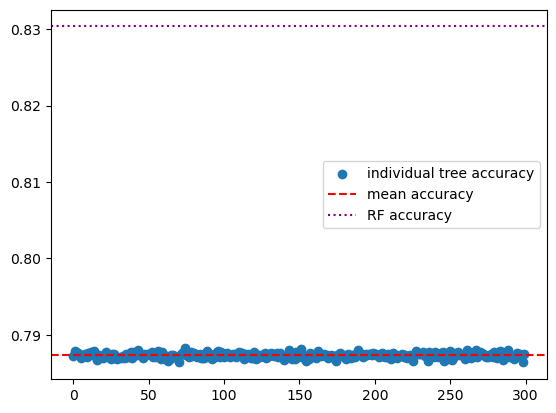

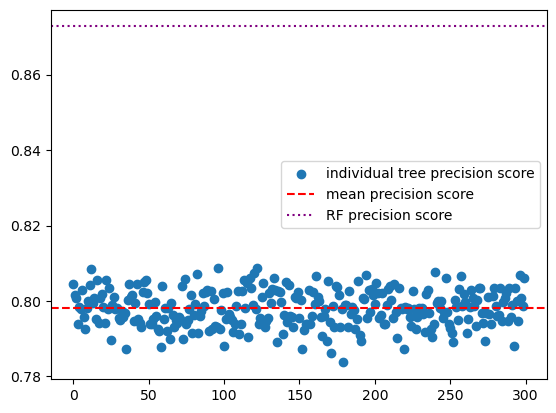

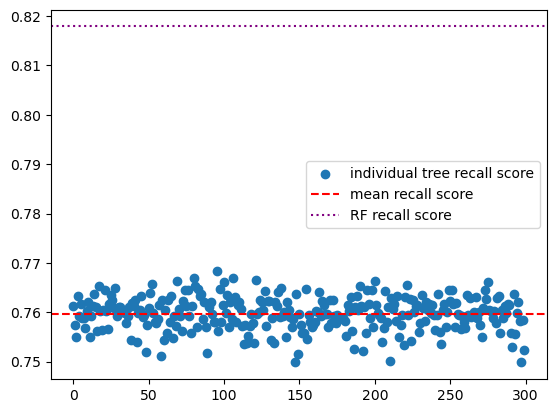

Done
2026-05-03 17:47:24
0.8447131213904032
0.8837398870070361
0.8350212518917504


In [7]:
"""
The other part of the decision tree kept crashing
plt.figure()
for a in alpha_vals.keys():
    acc = alpha_vals[a]["accuracy"]
    plt.plot(a, acc, marker="^")
plt.show()
"""

plt.figure()
plt.scatter(range(len(tree_accuracies)), tree_accuracies, label="individual tree accuracy")
plt.axhline(np.mean(tree_accuracies), color = "red", linestyle="--", label="mean accuracy")
plt.axhline(rf_accuracy, color="purple", linestyle=":", label = "RF accuracy")
plt.legend()
plt.show()

plt.figure()
plt.scatter(range(len(tree_precisions)), tree_precisions, label="individual tree precision score")
plt.axhline(np.mean(tree_precisions), color="red", linestyle="--", label="mean precision score")
plt.axhline(rf_precision, color="purple", linestyle=":", label="RF precision score")
plt.legend()
plt.show()

plt.figure()
plt.scatter(range(len(tree_recall_scores)), tree_recall_scores, label="individual tree recall score")
plt.axhline(np.mean(tree_recall_scores), color="red", linestyle="--", label="mean recall score")
plt.axhline(rf_recall_score, color="purple", linestyle=":", label="RF recall score")
plt.legend()
plt.show()
print("Done")
print(strftime("%Y-%m-%d %H:%M:%S", localtime()))


rf_final = RandomForestClassifier(n_estimators=300, max_depth=40, min_samples_split=2, min_samples_leaf=1, bootstrap=True)
rf.fit(X_validate, y_validate)
rf_final_accuracy = accuracy_score(y_validate, rf.predict(X_validate))
rf_final_precision = precision_score(y_validate, rf.predict(X_validate), average="macro")
rf_final_recall = recall_score(y_validate, rf.predict(X_validate), average="macro")
print(rf_final_accuracy)
print(rf_final_precision)
print(rf_final_recall)

# analyze / explain experimental results

Decision Trees and DnD are evidently a tumultuous pairing, especially when you have over one million rows in your dataset. That said, I had to play around with hyperparameters and eventually the train test split in order for my decision tree cross validation to run in less than 30 minutes (or MUCH MUCH longer). I eventually made a smaller training set to tune hyperparameters on, but the runtime was still not ideal. I changed the max_depth, min_sample_split, and min_sample_leaf, into various different configurations but the performance (both in runtime and results) were not very good. These parameters helped filter splits and leaves so that the trees wouldn't split/leaf if only one sample fit. They also limited the trees from being too big, which can make the runtime swell fast. The finishing blow to decision trees was that I couldn't get the accuracy to reach even 70%, which was my bare minimum percent I'd set for myself. That led me to try other options, starting with a Random Forest. Almost immediately I noticed that RFs were a lot more accurate than the trees on their own, but I still tweaked the hyperparameters some. I played around with essentially the same things as with the decision trees, just with the addition of n_estimators. I eventually settled on the current parameters after 3 previous runs with min_leaf = [20,10,1], min_split = [25, 15, 2], max_depth = [20, 30, 40]. I also had boostrap set to true for all but the first trial because my dataset is very large. I ended up with a final accuracy score of 0.844, a precision score of 0.883, and a recall score of 0.835 which I am happy with.

# conclusion 

In my dataset I was seeking to predict a characters starting class based on the stat totals they posses. The reasoning behind this is that a typical DnD class has a stats it favors and stats it doesn't. For instance, a Barbarian is a simple class, they want strength and constitution becasue they're goal is to deal and take as much damage as possible, essentially the tank of the party, but they couldn't care less about Intelligence as it pertains mostly to spell casting, a thing barbarians don't get access to without help. On the other side of that coin, a Wizard really wants Intelligence and Wisdom, because they buff the power of their spells and allows them to cast more spells without resting; that said a wizard is almost never hitting something with a physical weapon making strength all but useless to them. There is only one glaring flaw in this logic, some people roll for their stats, meaning they can be entirely random at the begining of a campaign. Stat rolls are typically done after a character is made, so if someone had their heart set on playing a Wizard and then rolled abysmal intelligence and high strength, nine times out of ten they'll still play the wizard despite not having the stats to match. That was my major concern going into this project, but it didn't seem to affect the accuracy all that much. I suspect that is because I overestimated how often that type of outlier would occur, or potentially someone rerolling their stats to better fit the archetype of the class they want. Moving onto the actual machine learning part, I tried decision trees and random forests, with KNN in my back pocket if neither worker very well. I set my project up this way because dts and rfs are very similar to one another, so if neither worked, a pivot to a distance based classifer might work better. The decison tree didnt work very well and I think at least part of the reasoning for this is that while high strength and constitution are hallmarks of a barbarian they are also common with paladins and fighters, similar things exist with wizards and other spellcasters. A single tree requires more rigid differences and doesn't handle the overlap well. That is why the random forset worked better, it covered more edge cases and then combined those to get the sum of it's parts. Ultimately I found that the majority of classes can be predicted but there are still some errors. I have a feeling the issues I brought up before might be showing themselves here and can account for at least some of the incorrectly classifed characters.